# EDA on merged_dataset_v1.csv
Workforce Pell Opportunity Score, Sage Road Solutions (Task #3)

Goal: confirm the merged data is trustworthy and model-ready, and write down what we find so the
feature dictionary (Task #4) and baseline model (Task #5) can build on it.

Fill in the `CONFIG` cell first, then run top to bottom. Each section ends with a short
"what to write down" note for the findings doc.

## 0. Setup and load

In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 200)

In [3]:
# ===== CONFIG: edit these =====
# Path to the shared folder file. If it is in "Shared with me", right click > Organize > Add shortcut to My Drive first.
PATH = '/Users/gabbyismeeee/Library/CloudStorage/GoogleDrive-gbui@macalester.edu/My Drive/merged_dataset_v1.csv'

# Set these once you see the column list in step 1. Leave as None if not present yet.
INST_ID   = 'UNITID'   # e.g. 'UNITID'
CIP_COL   = 'CIPCODE'   # e.g. 'CIPCODE'
SOC_COL   = 'OCC_CODE'
GEO_COL   = 'CBSA Code'
STATE_COL = 'STABBR'
LABEL     = None   # the label Victoria is locking in Task #1
GROUP_COLS = ['CONTROL_inst', 'LOCALE', 'CCSIZSET', 'HBCU', 'HSI', 'TRIBAL']

In [4]:
# Peek first so we do not crash Colab on an 800 MB file
head = pd.read_csv(PATH, nrows=5000, low_memory=False)
print(head.shape)
print(list(head.columns))
head.head()

overview = pd.DataFrame({
    'column': head.columns,
    'pct_filled': (head.notna().mean() * 100).round(1).values,
    'example': [head[c].dropna().iloc[0] if head[c].notna().any() else None for c in head.columns],
})
print('Completely empty columns:', (overview['pct_filled'] == 0).sum())
print('Mostly empty (under 20% filled):', (overview['pct_filled'] < 20).sum())
overview.to_csv('../column_overview.csv', index=False)

(5000, 3510)
['UNITID', 'OPEID6_program', 'INSTNM_program', 'CONTROL_program', 'MAIN_program', 'CIPCODE', 'CIPDESC', 'CREDLEV', 'CREDDESC', 'IPEDSCOUNT1', 'IPEDSCOUNT2', 'DEBT_ALL_STGP_ANY_N', 'DEBT_ALL_STGP_ANY_MEAN', 'DEBT_ALL_STGP_ANY_MDN', 'DEBT_ALL_STGP_EVAL_N', 'DEBT_ALL_STGP_EVAL_MEAN', 'DEBT_ALL_STGP_EVAL_MDN', 'DEBT_ALL_PP_ANY_N', 'DEBT_ALL_PP_ANY_MEAN', 'DEBT_ALL_PP_ANY_MDN', 'DEBT_ALL_PP_EVAL_N', 'DEBT_ALL_PP_EVAL_MEAN', 'DEBT_ALL_PP_EVAL_MDN', 'DEBT_MALE_STGP_ANY_N', 'DEBT_MALE_STGP_ANY_MEAN', 'DEBT_MALE_STGP_ANY_MDN', 'DEBT_MALE_STGP_EVAL_N', 'DEBT_MALE_STGP_EVAL_MEAN', 'DEBT_MALE_STGP_EVAL_MDN', 'DEBT_MALE_PP_ANY_N', 'DEBT_MALE_PP_ANY_MEAN', 'DEBT_MALE_PP_ANY_MDN', 'DEBT_MALE_PP_EVAL_N', 'DEBT_MALE_PP_EVAL_MEAN', 'DEBT_MALE_PP_EVAL_MDN', 'DEBT_NOTMALE_STGP_ANY_N', 'DEBT_NOTMALE_STGP_ANY_MEAN', 'DEBT_NOTMALE_STGP_ANY_MDN', 'DEBT_NOTMALE_STGP_EVAL_N', 'DEBT_NOTMALE_STGP_EVAL_MEAN', 'DEBT_NOTMALE_STGP_EVAL_MDN', 'DEBT_NOTMALE_PP_ANY_N', 'DEBT_NOTMALE_PP_ANY_MEAN', 'DEBT_NOTM

In [5]:
cols = list(head.columns)
program_cols = cols[:cols.index('OPEID6_inst')]
inst_keep = ['INSTNM_inst', 'CITY', 'STABBR', 'ZIP', 'ST_FIPS', 'REGION', 'LOCALE', 'LOCALE2',
             'LATITUDE', 'LONGITUDE', 'CONTROL_inst', 'PREDDEG', 'HIGHDEG', 'CCBASIC', 'CCSIZSET',
             'DISTANCEONLY', 'OPENADMP', 'ADM_RATE', 'HBCU', 'PBI', 'ANNHI', 'TRIBAL', 'AANAPII',
             'HSI', 'NANTI', 'MENONLY', 'WOMENONLY', 'UGDS', 'UGDS_WHITE', 'UGDS_BLACK', 'UGDS_HISP',
             'PCTPELL', 'PCTFLOAN', 'PAR_ED_PCT_1STGEN', 'TUITIONFEE_IN', 'TUITIONFEE_OUT',
             'NPT4_PUB', 'NPT4_PRIV', 'C150_4', 'C150_L4', 'RET_FT4', 'RET_FTL4', 'MD_EARN_WNE_P10']
linked_cols = cols[cols.index('SCORECARD_SECTOR'):]
keep = program_cols + inst_keep + linked_cols
print(len(keep), 'columns kept out of', len(cols))

250 columns kept out of 3510


In [6]:
# Full load with smaller dtypes. If Colab runs out of RAM, set USE_SAMPLE = True.
USE_SAMPLE = False
id_like = [c for c in head.columns if any(k in c.upper() for k in ['UNITID','CIP','SOC','OCC_CODE','FIPS','CBSA','ZIP','OPEID'])]
dtypes = {c: 'string' for c in id_like}   # keep codes as text so leading zeros survive

if USE_SAMPLE:
    df = pd.read_csv(PATH, usecols=keep, dtype=dtypes, low_memory=False)
else:
    df = pd.read_csv(PATH, usecols=keep, dtype=dtypes, low_memory=False)

for c in df.select_dtypes('float64').columns:
    df[c] = pd.to_numeric(df[c], downcast='float')
for c in df.select_dtypes('int64').columns:
    df[c] = pd.to_numeric(df[c], downcast='integer')

print(df.shape)
print(f"{df.memory_usage(deep=True).sum()/1e9:.2f} GB in memory")

(43465, 250)
0.10 GB in memory


In [7]:
df.to_parquet('../data/merged_slim.parquet', index=False)

In [8]:
print(df['CREDDESC'].value_counts())

CREDDESC
Undergraduate Certificate or Diploma    43465
Name: count, dtype: int64


{'Earnings, 1 yr after': np.float64(14.098700103531577), 'Earnings, 2 yr after': np.float64(14.413896238352697), 'Median debt': np.float64(12.357068906016334), 'Occupation wage (OEWS)': np.float64(56.647877602668814), 'County income (ACS)': np.float64(94.48981939491546)}


findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font f

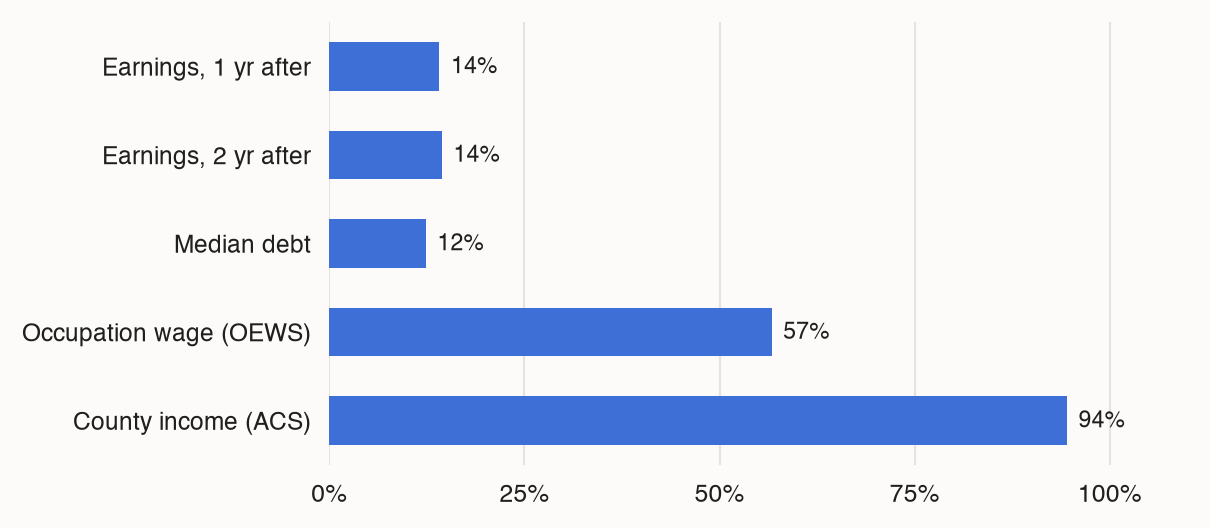

In [9]:
import matplotlib.patches as mpatches
plt.rcParams['font.family'] = ['Inter', 'Helvetica', 'Arial']
BG, INK, MUTED, GRID, BLUE = '#FCFBF9', '#1F1F1F', '#6B6B6B', '#E6E3DE', '#3D6FD6'

key = {'Earnings, 1 yr after': 'EARN_MDN_HI_1YR', 'Earnings, 2 yr after': 'EARN_MDN_HI_2YR',
       'Median debt': 'DEBT_ALL_STGP_EVAL_MDN', 'Occupation wage (OEWS)': 'A_MEDIAN',
       'County income (ACS)': 'B19013_001E'}
pct = {k: pd.to_numeric(df[v], errors='coerce').notna().mean() * 100 for k, v in key.items()}
print(pct)

fig, ax = plt.subplots(figsize=(5.6, 2.5), dpi=220)
fig.patch.set_facecolor(BG); ax.set_facecolor(BG)
names, vals = list(pct)[::-1], list(pct.values())[::-1]
ax.barh(names, vals, height=0.55, color=BLUE)
for i, v in enumerate(vals):
    ax.text(v + 1.5, i, f'{v:.0f}%', va='center', fontsize=7.5, color=INK)
ax.set_xlim(0, 110); ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xticklabels(['0%', '25%', '50%', '75%', '100%'], fontsize=7.5, color=MUTED)
ax.tick_params(length=0, pad=6, labelsize=8, labelcolor=INK)
ax.grid(axis='x', color=GRID, linewidth=0.7); ax.set_axisbelow(True)
for s in ax.spines.values(): s.set_visible(False)
plt.tight_layout(); plt.savefig('../outcomes_reported.png', facecolor=BG); plt.show()

## 1. What is one row? (most important check)
All four raw sources together are listed as under 1 GB, but the merged file is about 820 MB.
That can mean the join multiplied rows, most often through the CIP to SOC crosswalk
(one program maps to several occupations, and each occupation repeats for every metro).
If one row is supposed to be one institution or one program, duplicates here will
inflate every count and leak information across train and test splits later.

**Write down:** the intended unit of analysis, the actual number of rows per unit, and whether
the join needs to be fixed or aggregated before modeling.

In [10]:
print('rows:', len(df))
for col in [INST_ID, CIP_COL, SOC_COL, GEO_COL]:
    if col: print(f'unique {col}:', df[col].nunique())

if INST_ID:
    per_inst = df.groupby(INST_ID).size()
    print('\nrows per institution:'); print(per_inst.describe())
if INST_ID and CIP_COL:
    per_prog = df.groupby([INST_ID, CIP_COL]).size()
    print('\nrows per institution x program:'); print(per_prog.describe())
    print('programs with >1 row:', (per_prog > 1).sum())

print('\nfully duplicated rows:', df.duplicated().sum())

rows: 43465
unique UNITID: 4723
unique CIPCODE: 381
unique OCC_CODE: 136
unique CBSA Code: 719

rows per institution:
count    4723.000000
mean        9.011645
std        12.320050
min         1.000000
25%         1.000000
50%         3.000000
75%        12.000000
max        91.000000
dtype: float64

rows per institution x program:
count    42562.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
dtype: float64
programs with >1 row: 0

fully duplicated rows: 0


## 2. Column inventory and data types
Catch numbers stored as text (Scorecard uses 'PrivacySuppressed', OEWS uses '*' and '#'),
codes that lost leading zeros, and columns that are constant or almost all one value.

In [11]:
inv = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'n_unique': df.nunique(dropna=True),
    'pct_missing': (df.isna().mean()*100).round(1),
    'example': df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
}).sort_values('pct_missing', ascending=False)
inv

,dtype,n_unique,pct_missing,example
LOCALE2,float32,0,100.0,None
EARN_MDN_1YR_CLEAN,float32,4919,84.1,63335.0
PLACEMENT_RATE,float32,1400,84.1,1.0
ADM_RATE,float32,882,83.4,0.8818
NPT4_PRIV,float32,2376,82.5,14347.0
...,...,...,...,...
EARN_P25_4YR_NAT,str,215,0.0,34385
EARN_P75_4YR_NAT,str,225,0.0,72756
CIP_FAMILY,string,47,0.0,16
CREDDESC,str,1,0.0,Undergraduate Certificate or Diploma


In [12]:
# Suppression markers hiding as text
markers = ['PrivacySuppressed', 'PS', '*', '**', '#', 'NULL', 'NA', '-', '']
obj_cols = df.select_dtypes(['object', 'string']).columns
hits = {c: int(df[c].isin(markers).sum()) for c in obj_cols}
hits = {c: n for c, n in hits.items() if n > 0}
print(hits)

# Text columns that are mostly numeric (probably should be numbers)
for c in obj_cols:
    conv = pd.to_numeric(df[c], errors='coerce')
    share = conv.notna().mean()
    if 0.5 < share < 1 and c not in id_like:
        print(f'{c}: {share:.0%} numeric, likely needs cleaning')

{'DEBT_ALL_STGP_ANY_N': 30465, 'DEBT_ALL_STGP_ANY_MEAN': 30432, 'DEBT_ALL_STGP_ANY_MDN': 31215, 'DEBT_ALL_STGP_EVAL_N': 31726, 'DEBT_ALL_STGP_EVAL_MEAN': 31776, 'DEBT_ALL_STGP_EVAL_MDN': 32108, 'DEBT_ALL_PP_ANY_N': 35113, 'DEBT_ALL_PP_ANY_MEAN': 34787, 'DEBT_ALL_PP_ANY_MDN': 35532, 'DEBT_ALL_PP_EVAL_N': 35720, 'DEBT_ALL_PP_EVAL_MEAN': 35498, 'DEBT_ALL_PP_EVAL_MDN': 35961, 'DEBT_MALE_STGP_ANY_N': 35905, 'DEBT_MALE_STGP_ANY_MEAN': 35611, 'DEBT_MALE_STGP_ANY_MDN': 35817, 'DEBT_MALE_STGP_EVAL_N': 36049, 'DEBT_MALE_STGP_EVAL_MEAN': 35926, 'DEBT_MALE_STGP_EVAL_MDN': 36022, 'DEBT_MALE_PP_ANY_N': 37048, 'DEBT_MALE_PP_ANY_MEAN': 37008, 'DEBT_MALE_PP_ANY_MDN': 37222, 'DEBT_MALE_PP_EVAL_N': 37135, 'DEBT_MALE_PP_EVAL_MEAN': 37118, 'DEBT_MALE_PP_EVAL_MDN': 37253, 'DEBT_NOTMALE_STGP_ANY_N': 35905, 'DEBT_NOTMALE_STGP_ANY_MEAN': 35302, 'DEBT_NOTMALE_STGP_ANY_MDN': 35796, 'DEBT_NOTMALE_STGP_EVAL_N': 36049, 'DEBT_NOTMALE_STGP_EVAL_MEAN': 35623, 'DEBT_NOTMALE_STGP_EVAL_MDN': 36008, 'DEBT_NOTMALE_PP_ANY_N

In [13]:
# Code formatting checks
if CIP_COL: print('CIP lengths:', df[CIP_COL].dropna().astype(str).str.len().value_counts().head())
if SOC_COL: print('SOC sample:', df[SOC_COL].dropna().unique()[:10])
const_cols = [c for c in df.columns if df[c].nunique(dropna=True) <= 1]
print('constant columns (candidates to drop):', const_cols)

CIP lengths: CIPCODE
4    41206
3     2259
Name: count, dtype: int64
SOC sample: <ArrowStringArray>
['25-1071', '25-1011', '13-2011', '11-3021', '11-2021', '11-9199', '15-1221', '13-1151', '25-1081', '25-2011']
Length: 10, dtype: string
constant columns (candidates to drop): ['CREDLEV', 'CREDDESC', 'LOCALE2', 'EARN_THR_NAT']


## 3. Missingness
Not just how much is missing, but *who* is missing. Scorecard and OEWS suppress small cells,
which hits rural and small colleges hardest. If missingness tracks institution type,
dropping rows would quietly remove the colleges the project cares most about.

**Write down:** columns above ~40% missing, which ones look suppressed vs never collected,
and whether missingness differs by group.

findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font f

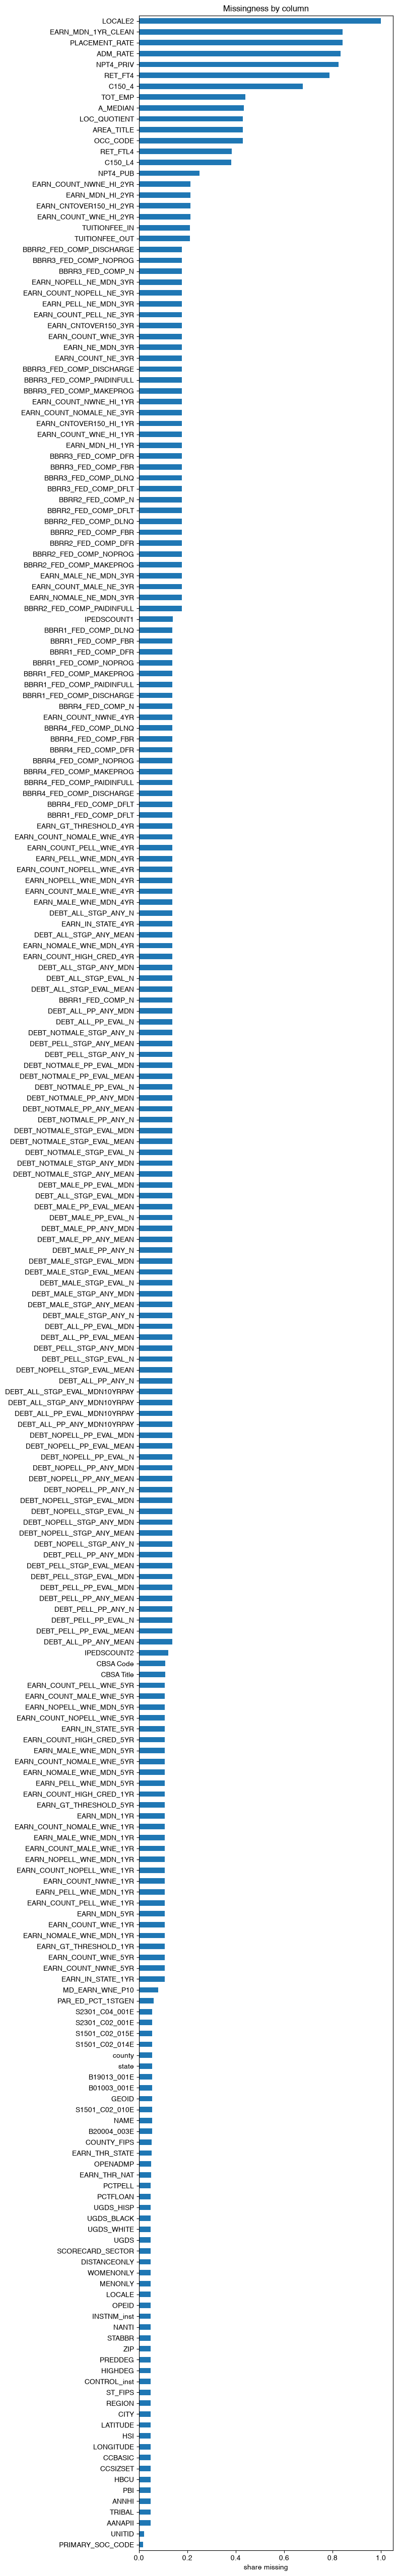

In [14]:
miss = df.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
plt.figure(figsize=(8, max(3, len(miss)*0.22)))
miss.plot.barh(); plt.gca().invert_yaxis()
plt.xlabel('share missing'); plt.title('Missingness by column'); plt.tight_layout(); plt.show()

findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font f

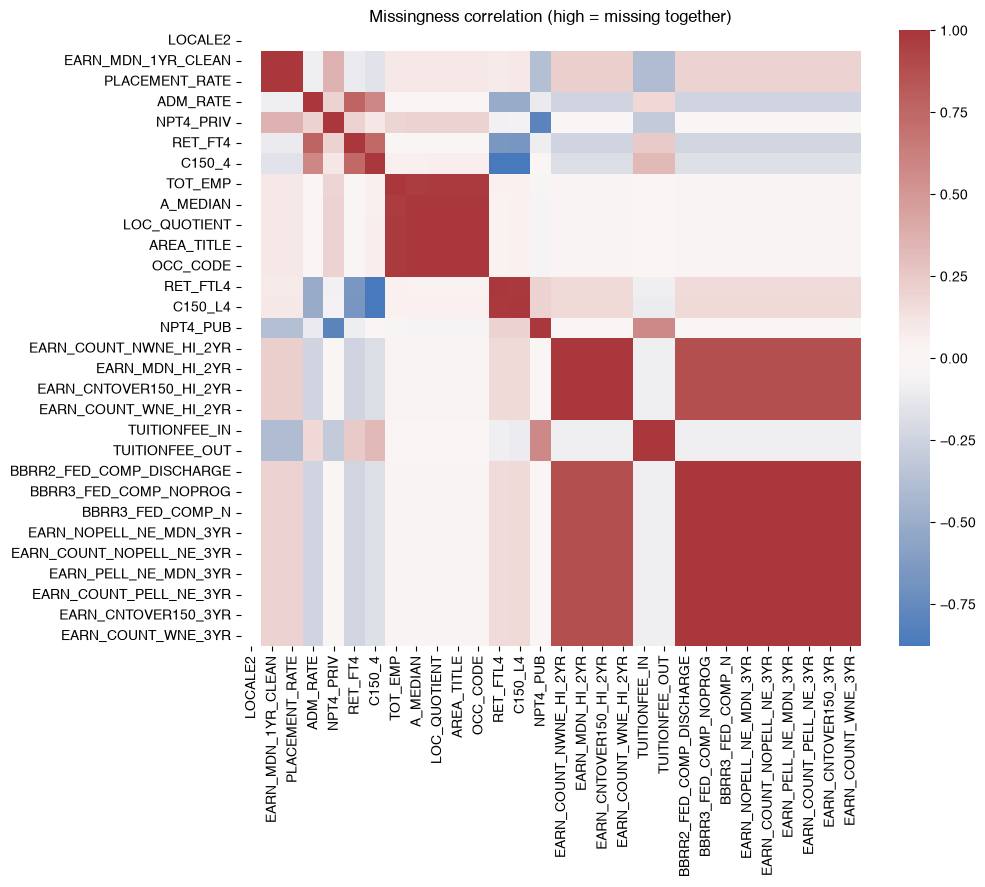

In [15]:
# Do columns go missing together (same source failing to join)?
top_miss = miss.head(30).index
if len(top_miss) > 1:
    plt.figure(figsize=(10, 8))
    sns.heatmap(df[top_miss].isna().corr(), cmap='vlag', center=0)
    plt.title('Missingness correlation (high = missing together)'); plt.show()

In [16]:
# Missingness by group (rural, control, MSI, state)
for g in GROUP_COLS + ([STATE_COL] if STATE_COL else []):
    if g in df.columns:
        print(f'\n=== share missing by {g} (top missing columns) ===')
        print(df.groupby(g)[list(miss.head(8).index)].apply(lambda x: x.isna().mean()).round(2))


=== share missing by CONTROL_inst (top missing columns) ===
              LOCALE2  EARN_MDN_1YR_CLEAN  PLACEMENT_RATE  ADM_RATE  NPT4_PRIV  RET_FT4  C150_4  TOT_EMP
CONTROL_inst                                                                                            
1.0               1.0                0.92            0.92      0.86       1.00     0.81    0.68     0.46
2.0               1.0                0.87            0.87      0.31       0.04     0.20    0.16     0.32
3.0               1.0                0.37            0.37      0.93       0.07     0.89    0.84     0.18

=== share missing by LOCALE (top missing columns) ===
        LOCALE2  EARN_MDN_1YR_CLEAN  PLACEMENT_RATE  ADM_RATE  NPT4_PRIV  RET_FT4  C150_4  TOT_EMP
LOCALE                                                                                            
-3.0        1.0                1.00            1.00      0.35       1.00     0.35    0.16     1.00
 11.0       1.0                0.80            0.80      0.77 

## 4. The label
Check balance, how it was built, and whether any feature is basically the label in disguise.

In [17]:
if LABEL:
    print(df[LABEL].describe(include='all'))
    if df[LABEL].nunique() <= 10:
        print(df[LABEL].value_counts(normalize=True).round(3))
        df[LABEL].value_counts().plot.bar(title='Label balance'); plt.show()
    else:
        df[LABEL].hist(bins=50); plt.title('Label distribution'); plt.show()
    print('label missing:', df[LABEL].isna().mean().round(3))
else:
    print('Set LABEL in CONFIG once Task #1 is locked.')

Set LABEL in CONFIG once Task #1 is locked.


In [18]:
# Leakage scan: features suspiciously close to the label
if LABEL:
    y = pd.to_numeric(df[LABEL], errors='coerce')
    num = df.select_dtypes('number').drop(columns=[LABEL], errors='ignore')
    corr = num.corrwith(y).abs().sort_values(ascending=False)
    print(corr.head(15))
    print('\nAnything above ~0.9 is worth asking: was this used to build the label?')

## 5. Distributions and outliers
Earnings, wages, and enrollment are usually very right skewed, so a log version is often more useful.
Look for impossible values (negative wages, completion rates above 1, zero enrollment).

In [19]:
num_cols = [c for c in df.select_dtypes('number').columns if c not in (INST_ID,)]
desc = df[num_cols].describe(percentiles=[.01, .5, .99]).T
desc['skew'] = df[num_cols].skew()
desc.sort_values('skew', ascending=False)

,count,mean,std,min,1%,50%,99%,max,skew
MENONLY,41357.0,0.000073,8.516784e-03,0.000000,0.000000,0.000000,0.000000e+00,1.000000e+00,117.403854
WOMENONLY,41357.0,0.001064,3.260063e-02,0.000000,0.000000,0.000000,0.000000e+00,1.000000e+00,30.610468
IPEDSCOUNT2,38183.0,28.623602,1.003781e+02,0.000000,0.000000,6.000000,3.243600e+02,5.567000e+03,20.003782
IPEDSCOUNT1,37326.0,28.431013,9.890313e+01,0.000000,0.000000,6.000000,3.140000e+02,4.894000e+03,18.799204
ANNHI,41357.0,0.004643,6.797840e-02,0.000000,0.000000,0.000000,0.000000e+00,1.000000e+00,14.574673
DISTANCEONLY,41357.0,0.005029,7.074040e-02,0.000000,0.000000,0.000000,0.000000e+00,1.000000e+00,13.994677
TRIBAL,41357.0,0.005997,7.720590e-02,0.000000,0.000000,0.000000,0.000000e+00,1.000000e+00,12.797655
HBCU,41357.0,0.006988,8.330229e-02,0.000000,0.000000,0.000000,0.000000e+00,1.000000e+00,11.837271
NANTI,41357.0,0.009648,9.774894e-02,0.000000,0.000000,0.000000,0.000000e+00,1.000000e+00,10.033378
TOT_EMP,24316.0,3451.699219,8.055165e+03,30.000000,30.000000,710.000000,3.448000e+04,1.119300e+05,6.109026


findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font f

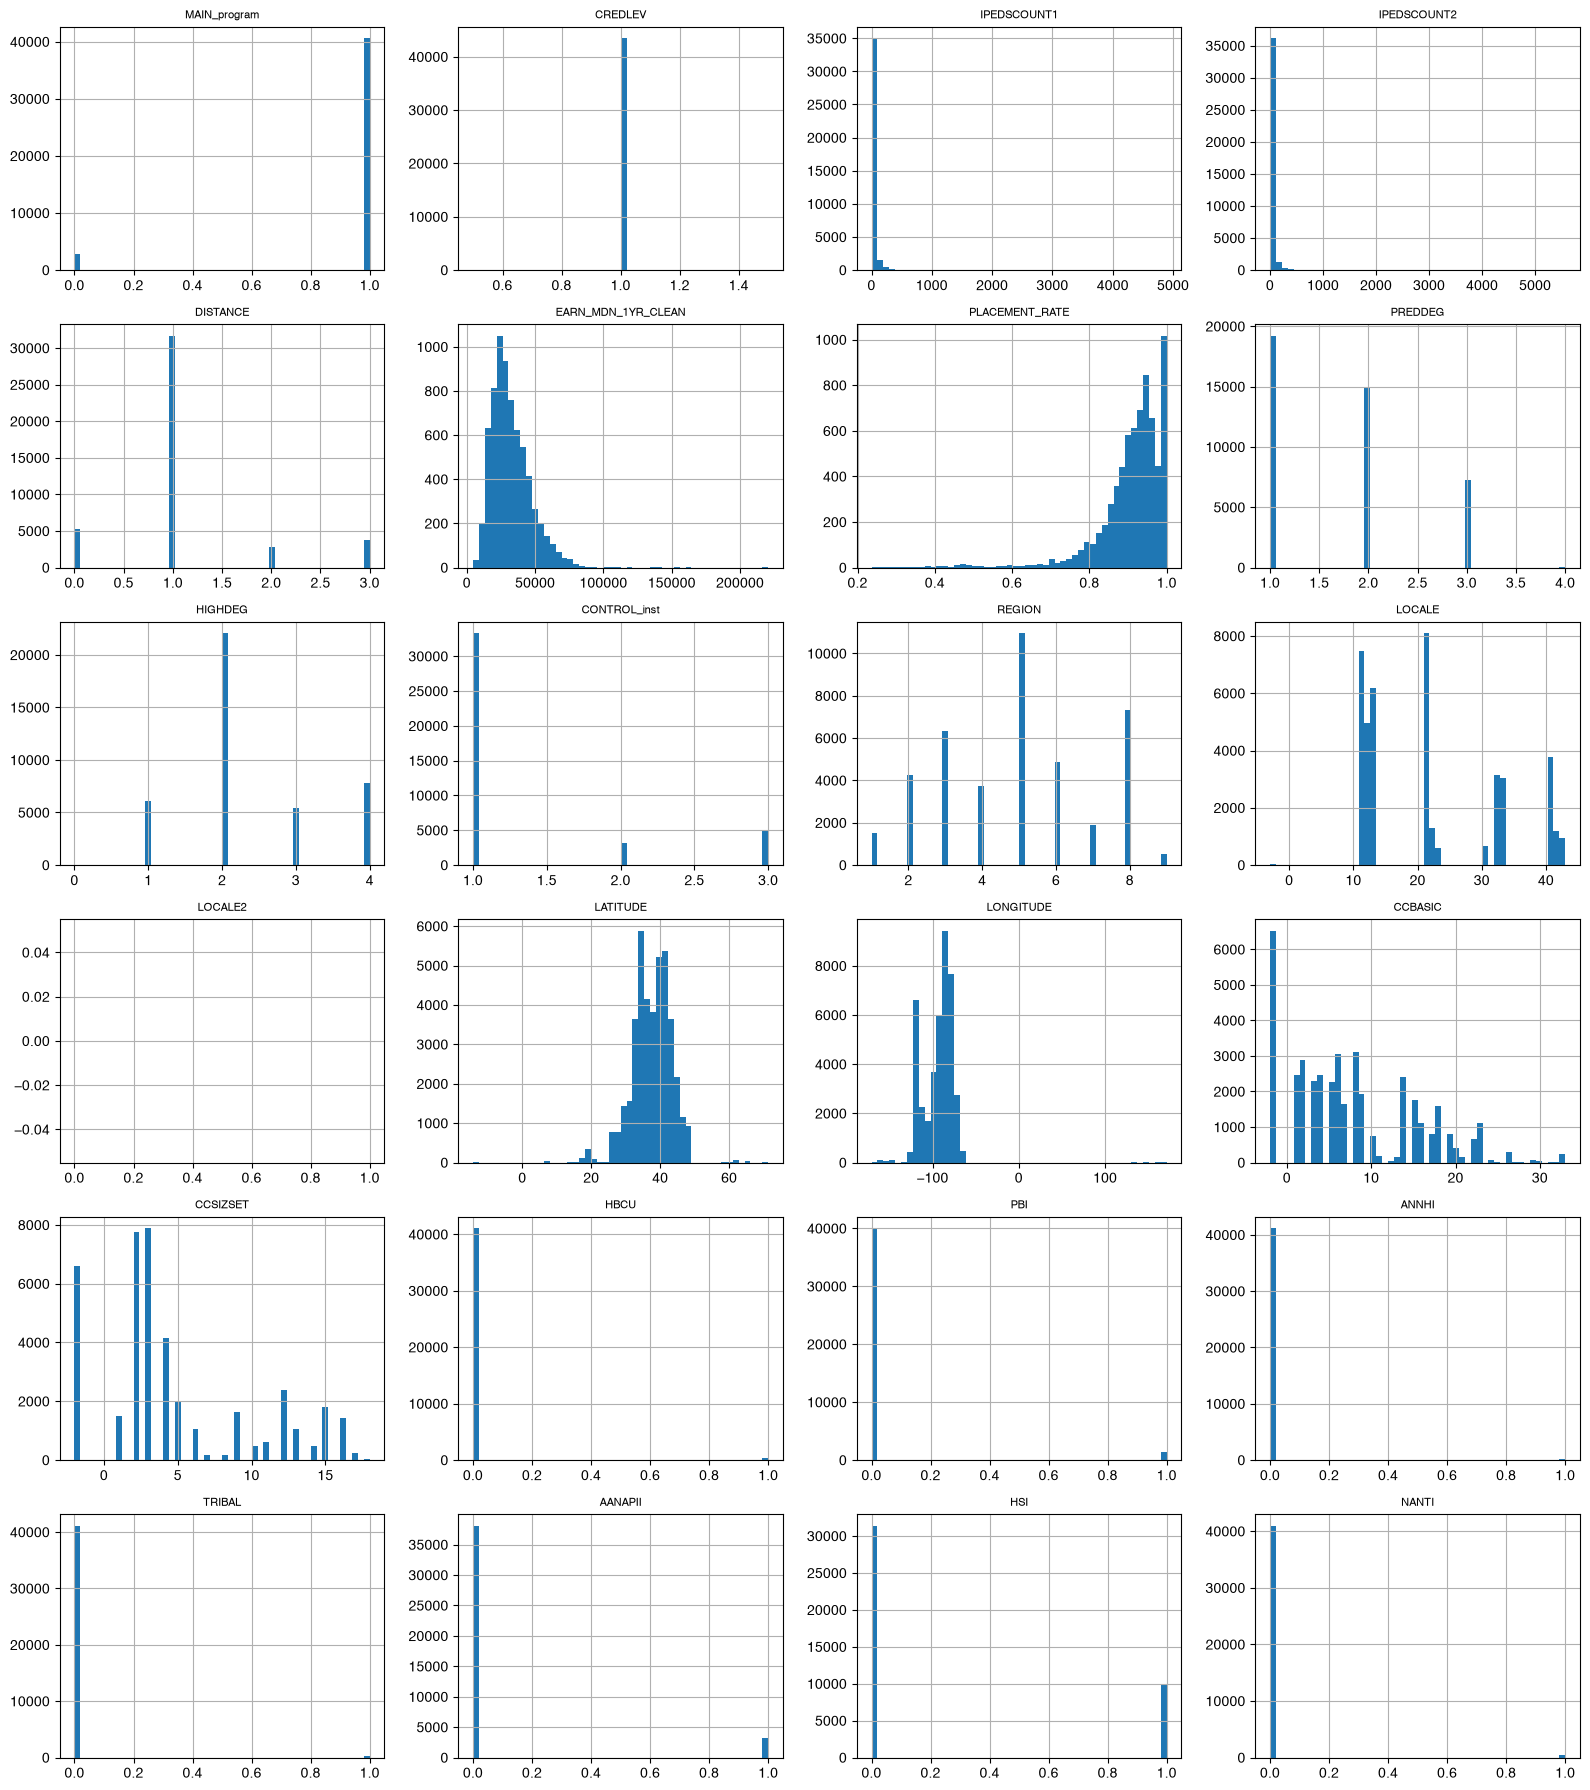

In [20]:
plot_cols = num_cols[:24]   # change the slice to page through the rest
n = len(plot_cols); rows = int(np.ceil(n/4))
fig, axes = plt.subplots(rows, 4, figsize=(16, 3*rows))
for ax, c in zip(axes.flat, plot_cols):
    df[c].dropna().hist(bins=50, ax=ax); ax.set_title(c, fontsize=8)
for ax in axes.flat[n:]: ax.axis('off')
plt.tight_layout(); plt.show()

## 6. Relationships between features

In [21]:
# Highly correlated pairs: candidates to drop or combine before modeling
c = df[num_cols].corr().abs()
pairs = (c.where(np.triu(np.ones(c.shape), 1).astype(bool)).stack().sort_values(ascending=False))
pairs[pairs > 0.85]

state          GEOID               0.999984
PREDDEG        SCORECARD_SECTOR    0.960451
IPEDSCOUNT1    IPEDSCOUNT2         0.929317
HIGHDEG        CCSIZSET            0.884913
TUITIONFEE_IN  TUITIONFEE_OUT      0.850183
dtype: float64

In [22]:
# Feature vs label, by group
if LABEL:
    for g in GROUP_COLS:
        if g in df.columns:
            df.groupby(g)[LABEL].agg(['mean', 'count']).plot.bar(y='mean', title=f'{LABEL} by {g}', legend=False)
            plt.show()

## 7. Geography
Check that every institution actually got matched to a labor market and a county,
and see how the label or key features vary across states and regions.

findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font f

rows with no geography match: 0.109


findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font f

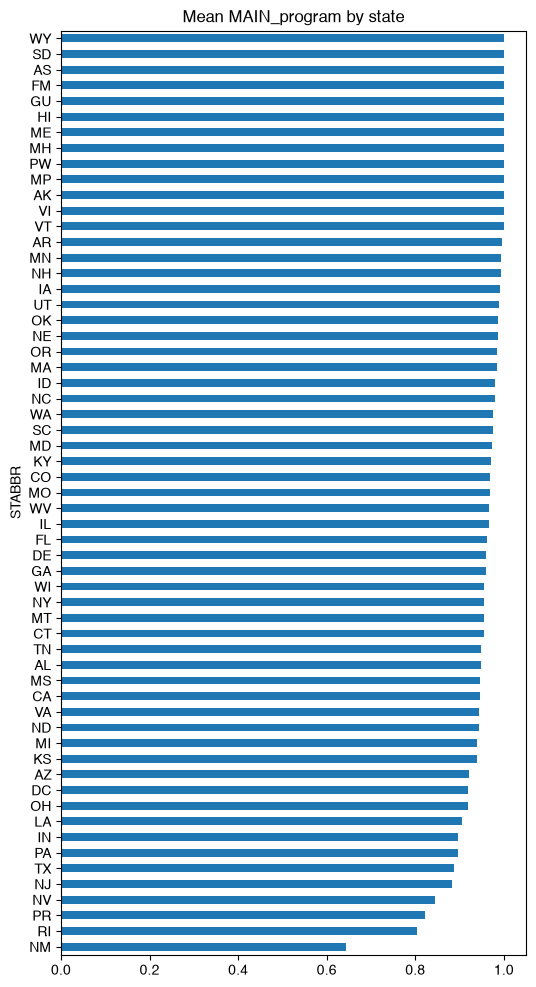

In [23]:
if GEO_COL:
    print('rows with no geography match:', df[GEO_COL].isna().mean().round(3))
if STATE_COL:
    agg_col = LABEL if LABEL else (num_cols[0] if num_cols else None)
    if agg_col:
        s = df.groupby(STATE_COL)[agg_col].mean().sort_values()
        s.plot.barh(figsize=(6, 12), title=f'Mean {agg_col} by state'); plt.show()